In [4]:
import subprocess, sys, os
def _pip(*p): subprocess.run([sys.executable,"-m","pip","install","-q",*p], check=False)
if "COLAB_RELEASE_TAG" in os.environ or "COLAB_GPU" in os.environ:   # install on Colab only
    _pip("xarray","netcdf4","cdsapi","global-land-mask","psutil")
print("deps ready")

deps ready


In [5]:
import os, gc, json, math, time, random, warnings, datetime
from dataclasses import dataclass, field
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
warnings.filterwarnings("ignore")
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED); torch.backends.cudnn.benchmark=True
    torch.backends.cuda.matmul.allow_tf32=True; torch.backends.cudnn.allow_tf32=True
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE=torch.bfloat16 if (DEVICE.type=="cuda" and torch.cuda.is_bf16_supported()) else torch.float16
print("torch",torch.__version__,"| device",DEVICE,"| amp",AMP_DTYPE)
if DEVICE.type=="cuda": print("GPU:",torch.cuda.get_device_name(0))
mpl.rcParams.update({"figure.dpi":120,"font.family":"serif","font.size":11,
    "axes.titlesize":12.5,"axes.spines.top":False,"axes.spines.right":False})
def _mem():
    try:
        import psutil; return f"RAM used {psutil.Process().memory_info().rss/2**30:.1f} GB"
    except Exception:
        return ""

torch 2.11.0+cu128 | device cuda | amp torch.bfloat16
GPU: NVIDIA A100-SXM4-80GB


In [6]:
BASE=Path("."); IN_COLAB=False
try:
    from google.colab import drive; drive.mount("/content/drive")
    BASE=Path("/content/drive/MyDrive/MSc Dissertation"); BASE.mkdir(parents=True,exist_ok=True)
    IN_COLAB=True
except Exception: print("Not on Colab — using local dir.")
print("BASE =",BASE.resolve())

Mounted at /content/drive
BASE = /content/drive/MyDrive/MSc Dissertation


In [7]:
@dataclass
class Config:
    RUN_MODE: str = "auto"
    AREA: tuple = (56.0,-6.0,50.0,2.0); GRID: float = 0.25
    YEARS: tuple = tuple(range(2015,2027))
    VARIABLES: tuple = (
        "10m_u_component_of_wind","10m_v_component_of_wind",
        "100m_u_component_of_wind","100m_v_component_of_wind",
        "instantaneous_10m_wind_gust","10m_wind_gust_since_previous_post_processing",
        "convective_available_potential_energy",
        "k_index","total_column_water_vapour","boundary_layer_height",
        "mean_sea_level_pressure","surface_pressure","2m_temperature","2m_dewpoint_temperature")
    RAW_DIR: Path = field(default_factory=lambda: BASE/"era5_england_raw_full")
    TIME_STRIDE: int = 1
    MAX_CELLS: int = 0
    LAND_ONLY: bool = True
    POT_Q: float = 0.98
    DECLUS_HRS: int = 24
    # survival task
    HIST: int = 48            # hours of input maps
    SURV_H: int = 48          # survival horizon (max lead modelled)
    COLLAPSE_L: int = 24      # lead at which the hazard is collapsed to the binary task
    LEADS: tuple = (6, 12, 24, 48)
    SAMPLE_STRIDE: int = 3
    TRAIN_FRAC: float = 0.70; VAL_FRAC: float = 0.15
    # model
    HID: int = 24; KSIZE: int = 3; DROPOUT: float = 0.3
    XI_CLAMP: float = 0.4; XI_INIT: float = -0.13
    # training
    BATCH: int = 8; EPOCHS: int = 30; LR: float = 1e-3
    WEIGHT_DECAY: float = 1e-2; PATIENCE: int = 10; LAMBDA_SEV: float = 0.5
    # continuous time hazard
    USE_ODE: bool = True          # False gives a discrete-time hazard
    DT_HOURS: float = 1.0         # integration step for Lambda(t)
    # physics informed terms
    USE_PHYSICS: bool = True
    LAMBDA_AUX: float = 0.3
    LAMBDA_PHYS: float = 0.05
    # shared severity target: the maximum excess in the next COLLAPSE_L hours, the
    # same quantity the binary models predict. The first-crossing GPD mark is kept
    # for the cause-specific tail results.
    USE_WMAX: bool = True
    LAMBDA_WMAX: float = 0.2      # weight on the window-max pinball term (log excess)
    WMAX_DETACH: bool = False     # True = stop gradients into the trunk
    QLEVELS: tuple = (0.10, 0.25, 0.50, 0.75, 0.90)   # MUST match the other notebooks
    # frozen-trunk refit of the window-max head (settings above are the survival model's)
    CKPT_NAME: str = "heich_cr_best.pt"   # 20 Sep occurrence checkpoint - read, never written
    REF_PR_AUC24: float = 0.5701          # published collapsed PR-AUC@24 (test) it must reproduce
    REPRO_TOL: float = 5e-4               # allowed |reproduced - reference|. The reference run used
                                          # bf16 autocast on an A100; fp32 on CPU moves the 4th decimal
                                          # by at most a few units. Anything larger means the inputs differ.
    FORCE_RECACHE: bool = False           # True = rebuild the feature cache even if a verified one exists
    HEAD_EPOCHS: int = 300; HEAD_PATIENCE: int = 30
    HEAD_LR: float = 1e-3; HEAD_WD: float = 1e-4; HEAD_BATCH: int = 8192

CFG=Config(); CFG.RAW_DIR.mkdir(parents=True,exist_ok=True)
assert CFG.COLLAPSE_L <= CFG.SURV_H and max(CFG.LEADS) <= CFG.SURV_H
assert CFG.QLEVELS == (0.10, 0.25, 0.50, 0.75, 0.90), "tau grid must match the other notebooks"
print("Config ready | RUN_MODE",CFG.RUN_MODE,"| SURV_H",CFG.SURV_H,"| RAW_DIR",CFG.RAW_DIR)

# Channel order of the survival model's map stack. Fixed here so the checkpoint can be loaded
# before any data is read; the feature cell asserts it builds exactly these channels.
CH_NAMES = ["cape","sqrt_cape","kx","tcwv","dd","wmaxshear",
            "msl","pgf","lap","vgeo","msl_tend",
            "ws10","ws100","gust","gust_factor","shear","wdir_sin","wdir_cos",
            "ws10_tend","adv","blh","t2m",
            "log_tsl","roll7","adi","cv2","sin_m","cos_m","sin_h","cos_h"]
LINEAR_NAMES = ["log_tsl","roll7","adi","cv2","cape","shear","wmaxshear",
                "pgf","msl_tend","adv","sin_m","cos_m","sin_h","cos_h"]
C = len(CH_NAMES); LINEAR_IDX = [CH_NAMES.index(n) for n in LINEAR_NAMES]
LIN_IDX_T = torch.tensor(LINEAR_IDX, dtype=torch.long)

# published numbers the new head is compared against (Table 4.4)
OLD_V3_SKILL, OLD_V3_COV = -8.9, 0.614      # v3 joint-trained survival head
CIGB_SKILL,   CIGB_COV   =  9.5, 0.777      # gradient-boosted trees

Config ready | RUN_MODE auto | SURV_H 48 | RAW_DIR /content/drive/MyDrive/MSc Dissertation/era5_england_raw_full


In [8]:
# files: everything written here has a _v4 name; the survival model's files are only read
import hashlib
CKPT         = BASE / CFG.CKPT_NAME
CKPT_V4      = BASE / "heich_cr_best_wmax_v4.pt"
CLIM_PATH    = BASE / "clim_wmax_train_v4.npy"
CACHE        = {sp: BASE / f"wmax_cache_v4_{sp}.npz" for sp in ("train", "val", "test")}
CACHE_META   = BASE / "wmax_cache_v4_meta.json"
RESULTS_JSON = BASE / "wmax_severity_results_v4.json"
FITLOG_JSON  = BASE / "wmax_head_fit_v4_log.json"
MAPS_DIR     = Path("/content/_v4_maps") if IN_COLAB else BASE / "_v4_maps"   # local disk, not Drive

def _md5_file(p, chunk=1 << 20):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()

assert CKPT.exists(), f"checkpoint not found: {CKPT}"
CKPT_MD5 = _md5_file(CKPT)
CKPT_MTIME = time.strftime("%Y-%m-%d %H:%M", time.localtime(CKPT.stat().st_mtime))
print(f"checkpoint {CKPT.name} | md5 {CKPT_MD5} | modified {CKPT_MTIME}")

_cache_ok = False
if CACHE_META.exists() and CLIM_PATH.exists() and all(p.exists() for p in CACHE.values()):
    _m = json.load(open(CACHE_META))
    _cache_ok = bool(_m.get("repro_passed")) and _m.get("ckpt_md5") == CKPT_MD5
    if not _cache_ok:
        print("existing feature cache does not match this checkpoint - it will be rebuilt")
NEED_CACHE = CFG.FORCE_RECACHE or not _cache_ok
print("STAGE A (data + reproduction check + feature cache):",
      "WILL RUN" if NEED_CACHE else "skipped - verified cache present")

# %%stage_a cells run only when the cache has to be (re)built.
from IPython.core.magic import register_cell_magic
@register_cell_magic
def stage_a(line, cell):
    if not NEED_CACHE:
        print("[stage A] skipped - verified feature cache present"); return
    exec(compile(cell, "<stage A cell>", "exec"), get_ipython().user_ns)

checkpoint heich_cr_best.pt | md5 b98d70d3bd9bda0331e1e5660acb7e3c | modified 2026-09-19 17:50
STAGE A (data + reproduction check + feature cache): WILL RUN


In [9]:
class ConvGRUCell(nn.Module):
    def __init__(self, in_ch, hid, k=3):
        super().__init__(); p=k//2
        self.z=nn.Conv2d(in_ch+hid,hid,k,padding=p); self.r=nn.Conv2d(in_ch+hid,hid,k,padding=p)
        self.n=nn.Conv2d(in_ch+hid,hid,k,padding=p); self.hid=hid
    def forward(self,x,h):
        xh=torch.cat([x,h],1); z=torch.sigmoid(self.z(xh)); r=torch.sigmoid(self.r(xh))
        n=torch.tanh(self.n(torch.cat([x,r*h],1))); return (1-z)*n+z*h

class HEICH_CR(nn.Module):
    def __init__(self, C, lin_idx, surv_h, hid=24, k=3, dropout=0.3, xi_clamp=0.4, xi_init=-0.13,
                 n_q=5, wmax_detach=False):
        super().__init__()
        self.register_buffer("lin_idx", lin_idx)
        self.cell=ConvGRUCell(C,hid,k); self.hid=hid; self.H=surv_h; self.xi_clamp=xi_clamp
        self.drop=nn.Dropout2d(dropout); n_lin=len(lin_idx)
        self.lin_haz=nn.Conv2d(n_lin, surv_h*3, 1)      # interpretable per-step/cause linear term
        self.ai_haz =nn.Conv2d(hid,   surv_h*3, 1)
        self.lin_sev=nn.Conv2d(n_lin, 1, 1); self.ai_sev=nn.Conv2d(hid, 1, 1)
        self.aux_dq =nn.Conv2d(hid, 1, 1)      # one hour gust tendency
        # window-maximum severity head.  Same shape as the hybrid's quantile head so
        # architecture is not a confound in the severity comparison.  Monotone by
        # construction: the first level is free, each later level adds a positive increment.
        self.n_q = n_q; self.wmax_detach = wmax_detach
        self.lin_wq = nn.Conv2d(n_lin, n_q, 1); self.ai_wq = nn.Conv2d(hid, n_q, 1)
        xi0=float(np.arctanh(np.clip(xi_init/xi_clamp,-0.99,0.99)))
        self.xi_conv=nn.Parameter(torch.tensor([xi0])); self.xi_syn=nn.Parameter(torch.tensor([xi0]))
        nn.init.zeros_(self.ai_haz.weight); nn.init.zeros_(self.ai_sev.weight)
        nn.init.zeros_(self.ai_wq.weight)
    def forward(self, x):                                # x: (B,HIST,C,nlat,nlon)
        B,Hh,C,Hy,Wx=x.shape
        h=torch.zeros(B,self.hid,Hy,Wx,device=x.device,dtype=x.dtype)
        for t in range(Hh): h=self.cell(x[:,t],h)
        h=self.drop(h); last=x[:,-1]; xlin=last.index_select(1,self.lin_idx)
        haz=(self.lin_haz(xlin)+self.ai_haz(h)).view(B,self.H,3,Hy,Wx)   # logits over {none,conv,syn}
        log_sig=(self.lin_sev(xlin)+self.ai_sev(h)).squeeze(1)
        sigma=F.softplus(log_sig)+1e-3
        xi_c=self.xi_clamp*torch.tanh(self.xi_conv); xi_s=self.xi_clamp*torch.tanh(self.xi_syn)
        dq = self.aux_dq(h).squeeze(1)
        hw = h.detach() if self.wmax_detach else h
        wq_raw = self.lin_wq(xlin) + self.ai_wq(hw)            # (B,n_q,nlat,nlon)
        wq = torch.cat([wq_raw[:, :1],
                        wq_raw[:, :1] + torch.cumsum(F.softplus(wq_raw[:, 1:]) + 1e-3, dim=1)], 1)
        return haz, sigma, xi_c, xi_s, dq, wq

def cumhazard(haz, dt):
    """Integrate dS/dt = -lambda(t) S(t).

    The network emits log intensities for the two competing causes. Softplus makes them positive,
    and the trapezoidal rule accumulates Lambda(t) = int_0^t (lam_c + lam_s) du, so that
    S(t) = exp(-Lambda(t)). Returns per cause intensities and the cumulative hazard.
    """
    lam = F.softplus(haz[:, :, 1:3])                 # (B,H,2,nlat,nlon), per hour
    tot = lam.sum(2)                                 # (B,H,nlat,nlon)
    # trapezoid: Lambda_k = dt * ( sum_{j<k} tot_j + tot_k/2 )
    cum = torch.cumsum(tot, dim=1) - 0.5*tot
    return lam, cum*dt

def trunk_forward(model, x):
    '''HEICH_CR.forward, line for line, additionally returning xlin and h.'''
    B,Hh,C_,Hy,Wx=x.shape
    h=torch.zeros(B,model.hid,Hy,Wx,device=x.device,dtype=x.dtype)
    for t in range(Hh): h=model.cell(x[:,t],h)
    h=model.drop(h); last=x[:,-1]; xlin=last.index_select(1,model.lin_idx)
    haz=(model.lin_haz(xlin)+model.ai_haz(h)).view(B,model.H,3,Hy,Wx)
    wq_raw = model.lin_wq(xlin) + model.ai_wq(h)
    wq = torch.cat([wq_raw[:, :1],
                    wq_raw[:, :1] + torch.cumsum(F.softplus(wq_raw[:, 1:]) + 1e-3, dim=1)], 1)
    return haz, xlin, h, wq

def head_from_features(xl, hh):
    '''The window-max head on cached rows: xl (N,14), hh (N,24) -> monotone log quantiles (N,n_q).'''
    nq = model.n_q
    raw = (F.linear(xl, model.lin_wq.weight.view(nq, -1), model.lin_wq.bias)
           + F.linear(hh, model.ai_wq.weight.view(nq, -1), model.ai_wq.bias))
    return torch.cat([raw[:, :1], raw[:, :1] + torch.cumsum(F.softplus(raw[:, 1:]) + 1e-3, dim=1)], 1)

In [10]:
model=HEICH_CR(C, LIN_IDX_T, CFG.SURV_H, CFG.HID, CFG.KSIZE, CFG.DROPOUT, CFG.XI_CLAMP,
               CFG.XI_INIT, len(CFG.QLEVELS), CFG.WMAX_DETACH).to(DEVICE)
_sd = torch.load(CKPT, map_location=DEVICE, weights_only=True)
model.load_state_dict(_sd, strict=True)
model.eval()                                   # dropout off for good: inference-only backbone

HEAD_PREFIX = ("lin_wq.", "ai_wq.")
for _n, _p in model.named_parameters():
    _p.requires_grad_(_n.startswith(HEAD_PREFIX))
_trainable = sorted(n for n, p in model.named_parameters() if p.requires_grad)
assert _trainable == ["ai_wq.bias", "ai_wq.weight", "lin_wq.bias", "lin_wq.weight"], _trainable
TRUNK_REF  = {k: v.detach().cpu().clone() for k, v in _sd.items() if not k.startswith(HEAD_PREFIX)}
HEAD_JOINT = {k: v.detach().cpu().clone() for k, v in _sd.items() if k.startswith(HEAD_PREFIX)}
del _sd
_nf = sum(p.numel() for p in model.parameters() if not p.requires_grad)
_nt = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"loaded {CKPT.name} | frozen {_nf:,} params | trainable {_nt} (lin_wq + ai_wq only)")

loaded heich_cr_best.pt | frozen 40,891 params | trainable 200 (lin_wq + ai_wq only)


In [11]:
%%stage_a
# ERA5 downloader (only used in RUN_MODE="full" or if you call it explicitly)
def download_era5(cfg):
    import cdsapi
    c = cdsapi.Client()
    cfg.RAW_DIR.mkdir(parents=True, exist_ok=True)
    N, W, S, E = cfg.AREA
    files = []
    for yr in cfg.YEARS:
        fp = cfg.RAW_DIR / f"era5_england_{yr}.nc"
        if fp.exists():
            print(f"  [{yr}] present — skip"); files.append(fp); continue
        print(f"  [{yr}] requesting from CDS …")
        try:
            c.retrieve("reanalysis-era5-single-levels", {
                "product_type": "reanalysis",
                "variable": list(cfg.VARIABLES),
                "year": str(yr),
                "month": [f"{m:02d}" for m in range(1, 13)],
                "day":   [f"{d:02d}" for d in range(1, 32)],
                "time":  [f"{h:02d}:00" for h in range(24)],
                "area":  [N, W, S, E],
                "grid":  [cfg.GRID, cfg.GRID],
                "format": "netcdf",
            }, str(fp))
            files.append(fp)
        except Exception as e:
            print(f"  [{yr}] failed: {e}")
    return files

RAW_FILES = sorted(CFG.RAW_DIR.glob("*.nc"))
print(f"NetCDF files found in {CFG.RAW_DIR}: {len(RAW_FILES)}")
if CFG.RUN_MODE == "full" and not RAW_FILES:
    RAW_FILES = sorted(download_era5(CFG))

NetCDF files found in /content/drive/MyDrive/MSc Dissertation/era5_england_raw_full: 276


In [12]:
%%stage_a
# canonical short-name mapping & robust ERA5 loader
RENAME = {
    "u10": "u10", "v10": "v10", "u100": "u100", "v100": "v100",
    "i10fg": "i10fg", "fg10": "fg10", "cape": "cape",
    "kx": "kx", "tcwv": "tcwv", "blh": "blh", "msl": "msl", "sp": "sp",
    "t2m": "t2m", "d2m": "d2m",
    # occasional alt names
    "10fg": "fg10", "instantaneous_10m_wind_gust": "i10fg",
}

def load_era5_netcdf(files, cfg):
    import xarray as xr
    ds = xr.open_mfdataset([str(f) for f in files], combine="by_coords",
                           engine="netcdf4", chunks={"time": 1500})
    # normalise coord names
    for a, b in [("latitude", "lat"), ("longitude", "lon"), ("valid_time", "time")]:
        if a in ds.dims or a in ds.coords:
            ds = ds.rename({a: b})
    # collapse ERA5T 'expver' if present
    if "expver" in ds.dims:
        ds = ds.mean("expver")
    elif "expver" in ds.coords:
        ds = ds.drop_vars("expver")
    ds = ds.rename({k: v for k, v in RENAME.items() if k in ds.variables})
    if cfg.TIME_STRIDE > 1:
        ds = ds.isel(time=slice(None, None, cfg.TIME_STRIDE))
    ds = ds.sortby("time").sortby("lat").sortby("lon")
    times = pd.DatetimeIndex(ds.time.values)
    lats = ds.lat.values.astype(np.float32)
    lons = ds.lon.values.astype(np.float32)
    fields = {}
    for name in ["u10","v10","u100","v100","i10fg","fg10","cape","kx","tcwv","blh","msl","sp","t2m","d2m"]:
        if name in ds.variables:
            fields[name] = ds[name].transpose("time","lat","lon").values.astype(np.float32)
    # unit tidy
    if "sp"  in fields: fields["sp"]  = fields["sp"] / 100.0     # Pa -> hPa
    if "msl" in fields: fields["msl"] = fields["msl"] / 100.0    # Pa -> hPa
    for k in ("t2m","d2m"):
        if k in fields: fields[k] = fields[k] - 273.15           # K -> degC
    ds.close()
    return times, lats, lons, fields

In [14]:
%%stage_a
# load ERA5
if not RAW_FILES:
    raise FileNotFoundError(f"no ERA5 NetCDF files found in {CFG.RAW_DIR}")
times, lats, lons, FIELDS = load_era5_netcdf(RAW_FILES, CFG)

nlat, nlon = len(lats), len(lons)
T = len(times)
print("ERA5 data loaded")
print(f"  time : {times[0]} -> {times[-1]}  ({T:,} steps, stride={CFG.TIME_STRIDE}h)")
print(f"  grid : {nlat} lat x {nlon} lon = {nlat*nlon} cells  |  vars: {sorted(FIELDS)}")

ERA5 data loaded
  time : 2015-01-01 00:00:00 -> 2026-06-30 19:00:00  (100,772 steps, stride=1h)
  grid : 25 lat x 33 lon = 825 cells  |  vars: ['blh', 'cape', 'd2m', 'fg10', 'i10fg', 'kx', 'msl', 'sp', 't2m', 'tcwv', 'u10', 'u100', 'v10', 'v100']


In [15]:
%%stage_a
# derived scalar fields + land mask + cell selection
def hypot(a, b): return np.sqrt(a*a + b*b)

FIELDS["ws10"]  = hypot(FIELDS["u10"], FIELDS["v10"]).astype(np.float32)
FIELDS["ws100"] = hypot(FIELDS["u100"], FIELDS["v100"]).astype(np.float32)
# gust: prefer instantaneous; fall back to fg10, then a gust-factor proxy
if "i10fg" in FIELDS:
    FIELDS["gust"] = FIELDS["i10fg"]
elif "fg10" in FIELDS:
    FIELDS["gust"] = FIELDS["fg10"]
else:
    FIELDS["gust"] = (1.4*FIELDS["ws10"]).astype(np.float32)

# clean sparse NaN gaps (real ERA5 has a few missing hours; NaN would poison
# percentiles/thresholds downstream). Interpolate in time per cell, then fill any
# fully-missing cell with the field mean.
def _clean_field(a):
    if not np.isnan(a).any():
        return a.astype(np.float32)
    Tt = a.shape[0]
    flat = pd.DataFrame(a.reshape(Tt, -1)).interpolate(limit_direction="both", axis=0)
    flat = flat.fillna(flat.mean())
    return flat.values.reshape(a.shape).astype(np.float32)

_nan_before = sum(int(np.isnan(v).sum()) for v in FIELDS.values())
if _nan_before:
    FIELDS = {k: _clean_field(v) for k, v in FIELDS.items()}
    _nan_after = sum(int(np.isnan(v).sum()) for v in FIELDS.values())
    print(f"NaN cleaning: {_nan_before:,} -> {_nan_after:,} missing values filled")

# land / coastal mask
land_mask = np.ones((nlat, nlon), dtype=bool)
if CFG.LAND_ONLY:
    try:
        from global_land_mask import globe
        LO, LA = np.meshgrid(lons, lats)
        land = globe.is_land(LA, LO)
        # keep land + one-cell coastal halo
        from scipy.ndimage import binary_dilation
        land_mask = binary_dilation(land, iterations=1)
        print(f"Land+coastal cells: {land_mask.sum()}/{land_mask.size}")
    except Exception as e:
        print("global_land_mask unavailable — keeping all cells:", e)

cell_ii, cell_jj = np.where(land_mask)
if CFG.MAX_CELLS and len(cell_ii) > CFG.MAX_CELLS:
    sel = np.linspace(0, len(cell_ii)-1, CFG.MAX_CELLS).astype(int)
    cell_ii, cell_jj = cell_ii[sel], cell_jj[sel]
N_CELLS = len(cell_ii)
print(f"Modelling {N_CELLS} cells | gust mean={FIELDS['gust'].mean():.2f}  max={FIELDS['gust'].max():.2f} m/s")

# drop raw fields the map stack and labels never use (saves RAM on a free runtime)
for _k in ("u100", "v100", "fg10", "sp"):
    if _k in FIELDS and FIELDS[_k] is not FIELDS["gust"]:
        del FIELDS[_k]
gc.collect(); print("fields kept:", sorted(FIELDS), "|", _mem())

NaN cleaning: 1,849,650 -> 0 missing values filled
Land+coastal cells: 520/825
Modelling 520 cells | gust mean=9.26  max=44.62 m/s
fields kept: ['blh', 'cape', 'd2m', 'gust', 'i10fg', 'kx', 'msl', 't2m', 'tcwv', 'u10', 'v10', 'ws10', 'ws100'] | RAM used 6.9 GB


In [16]:
%%stage_a
# chronological split, as in the survival notebook
nlat, nlon = len(lats), len(lons); ncell = nlat*nlon; eps = 1e-6
tstamp     = times.values.astype("datetime64[ns]")
_span      = tstamp[-1] - tstamp[0]
train_end  = tstamp[0] + _span*CFG.TRAIN_FRAC
val_end    = tstamp[0] + _span*(CFG.TRAIN_FRAC + CFG.VAL_FRAC)
is_train_t = tstamp <= train_end
N_TR_T = int(is_train_t.sum()); assert is_train_t[:N_TR_T].all(), "training period must be a prefix"
print(f"Split for feature statistics: train <= {str(train_end)[:10]}")

def _v3_stats(a):
    '''mean and std of one channel exactly as the survival notebook computes them (MAPS[train], axes 0, 2, 3).'''
    n = np.float32(a[0].size * a.shape[0]); r = a.reshape(a.shape[0], -1)
    mu = np.float32(np.cumsum(r.sum(axis=1), dtype=np.float32)[-1] / n)
    d = r - mu
    var = np.float32(np.cumsum((d*d).sum(axis=1), dtype=np.float32)[-1] / n)
    return mu, np.float32(np.sqrt(var))

MAPS_DIR.mkdir(parents=True, exist_ok=True)
MAPS_FILE = MAPS_DIR / "maps_v4_channel_major.npy"
MAPS_MM = np.lib.format.open_memmap(MAPS_FILE, mode="w+", dtype=np.float32, shape=(C, T, nlat, nlon))
CH_MEAN = np.zeros(C, np.float32); CH_STD = np.zeros(C, np.float32); _BUILT = []; _NANS = 0

def _put(name, arr):
    '''normalise one channel on training timesteps and write it to the memmap.'''
    global _NANS
    k = CH_NAMES.index(name); assert name not in _BUILT, name
    a = np.ascontiguousarray(arr, dtype=np.float32); assert a.shape == (T, nlat, nlon), (name, a.shape)
    mu, sd = _v3_stats(a[:N_TR_T]); sd = np.float32(sd + np.float32(1e-6))
    CH_MEAN[k], CH_STD[k] = mu, sd
    out = (a - mu) / sd
    _NANS += int(np.isnan(out).sum()); MAPS_MM[k] = out; _BUILT.append(name)
    del a, out; MAPS_MM.flush()           # push pages to disk so they do not count against RAM

t0 = time.time()
# synoptic
GRID_KM = CFG.GRID*111.32
dlat_km = GRID_KM
dlon_km = np.maximum(GRID_KM*np.cos(np.deg2rad(lats)), 1e-3)
msl = FIELDS["msl"]
gy = np.gradient(msl, axis=1)/dlat_km
gx = np.gradient(msl, axis=2)/dlon_km[None,:,None]
pgf = np.sqrt(gx*gx+gy*gy).astype(np.float32)
lap = (np.gradient(gy,axis=1)+np.gradient(gx,axis=2)).astype(np.float32)
del gy, gx
f_cor = np.maximum(2*7.292e-5*np.abs(np.sin(np.deg2rad(lats))), 2e-5)[None,:,None]
vgeo = (pgf*100.0/1000.0/(1.225*f_cor)).astype(np.float32)
_put("msl", msl); _put("pgf", pgf); _put("lap", lap); _put("vgeo", vgeo); del pgf, lap, vgeo
msl_tend = np.zeros_like(msl); msl_tend[3:] = msl[3:]-msl[:-3]
_put("msl_tend", msl_tend); del msl_tend
# kinematic
ws10, ws100, gustf = FIELDS["ws10"], FIELDS["ws100"], FIELDS["gust"]
shear = (ws100-ws10).astype(np.float32)
wdir = np.arctan2(FIELDS["v10"], FIELDS["u10"])
_put("wdir_sin", np.sin(wdir).astype(np.float32)); _put("wdir_cos", np.cos(wdir).astype(np.float32)); del wdir
def tend(a,k=3):
    o=np.zeros_like(a); o[k:]=a[k:]-a[:-k]; return o
# convective
cape=FIELDS["cape"]; sqrt_cape=np.sqrt(np.clip(cape,0,None)).astype(np.float32)
wmaxshear=(np.sqrt(2*np.clip(cape,0,None))*shear).astype(np.float32)
dd=(FIELDS["t2m"]-FIELDS["d2m"]).astype(np.float32)
_put("cape", cape); _put("sqrt_cape", sqrt_cape); _put("kx", FIELDS["kx"]); _put("tcwv", FIELDS["tcwv"])
_put("dd", dd); _put("wmaxshear", wmaxshear); del sqrt_cape, wmaxshear, dd
_put("ws10", ws10); _put("ws100", ws100); _put("gust", gustf); _put("gust_factor", gustf/(ws10+eps))
_put("shear", shear); _put("ws10_tend", tend(ws10)); _put("blh", FIELDS["blh"]); _put("t2m", FIELDS["t2m"])
del shear; gc.collect()
print(f"synoptic + kinematic + convective channels written ({time.time()-t0:.0f}s) | {_mem()}")

# intermittency state (training-period statistics only)
g2 = gustf.reshape(T, ncell)
thr_all = np.nanpercentile(g2[is_train_t], 98, axis=0)
exc = g2 > thr_all[None,:]
tsl = np.zeros_like(g2); last = np.full(ncell, -9999)
for t in range(T):
    tsl[t] = t-last; last = np.where(exc[t], t, last)
tsl = np.clip(tsl, 0, 24*30).astype(np.float32)
_put("log_tsl", np.log1p(tsl).reshape(T,nlat,nlon)); del tsl
win = 24*7
cs = np.cumsum(exc.astype(np.float32), axis=0)
roll7 = np.zeros_like(cs); roll7[win:]=cs[win:]-cs[:-win]; roll7[:win]=cs[:win]
_put("roll7", roll7.reshape(T,nlat,nlon)); del cs, roll7
tr_idx = np.flatnonzero(is_train_t); n_tr = tr_idx.size
exc_tr = exc[is_train_t]
nexc = np.maximum(exc_tr.sum(0),1)
adi_static = (n_tr/nexc).astype(np.float32)
cv2_static = np.ones(ncell, np.float32)
for c in range(ncell):
    v = g2[tr_idx[exc_tr[:,c]], c]
    if len(v) > 2: cv2_static[c] = (v.std(ddof=1)/(v.mean()+eps))**2
_put("adi", np.broadcast_to(adi_static.reshape(nlat,nlon)[None], (T,nlat,nlon)))
_put("cv2", np.broadcast_to(cv2_static.reshape(nlat,nlon)[None], (T,nlat,nlon)))
del exc, exc_tr
mo=times.month.values.astype(np.float32); ho=times.hour.values.astype(np.float32)
def bc(v): return np.broadcast_to(v[:,None,None], (T,nlat,nlon)).astype(np.float32)
_put("sin_m", bc(np.sin(2*np.pi*mo/12))); _put("cos_m", bc(np.cos(2*np.pi*mo/12)))
_put("sin_h", bc(np.sin(2*np.pi*ho/24))); _put("cos_h", bc(np.cos(2*np.pi*ho/24)))
# advective tendency
_ggy = np.gradient(gustf, axis=1) / dlat_km
_ggx = np.gradient(gustf, axis=2) / dlon_km[None, :, None]
_put("adv", (-(3.6*FIELDS["u10"]*_ggx + 3.6*FIELDS["v10"]*_ggy)).astype(np.float32))
del _ggy, _ggx; gc.collect()

assert sorted(_BUILT) == sorted(CH_NAMES) and len(_BUILT) == C, "channel set differs from v3"
MAPS_MM.flush(); del MAPS_MM; gc.collect()
MAPS_MM = np.load(MAPS_FILE, mmap_mode="r")
print(f"Map stack (C,T,lat,lon) = {MAPS_MM.shape} on disk at {MAPS_FILE} "
      f"({MAPS_MM.nbytes/2**30:.1f} GB) | NaNs: {_NANS} | {time.time()-t0:.0f}s | {_mem()}")

Split for feature statistics: train <= 2023-01-18
synoptic + kinematic + convective channels written (47s) | RAM used 13.4 GB
Map stack (C,T,lat,lon) = (30, 100772, 25, 33) on disk at /content/_v4_maps/maps_v4_channel_major.npy (9.3 GB) | NaNs: 0 | 71s | RAM used 6.9 GB


In [17]:
%%stage_a
nlat, nlon = len(lats), len(lons); ncell = nlat*nlon; eps=1e-6
tstamp = times.values.astype("datetime64[ns]")
span = tstamp[-1]-tstamp[0]
train_end = tstamp[0]+span*CFG.TRAIN_FRAC
val_end   = tstamp[0]+span*(CFG.TRAIN_FRAC+CFG.VAL_FRAC)
is_train_t = tstamp <= train_end
print(f"Split: train <= {str(train_end)[:10]} | val <= {str(val_end)[:10]} | test after")

# weak-supervised cause map (convective vs synoptic) from raw fields
GRID_KM=CFG.GRID*111.32; dlon_km=np.maximum(GRID_KM*np.cos(np.deg2rad(lats)),1e-3)
msl=FIELDS["msl"]; gy=np.gradient(msl,axis=1)/GRID_KM; gx=np.gradient(msl,axis=2)/dlon_km[None,:,None]
pgf=np.sqrt(gx*gx+gy*gy)
shear=(FIELDS["ws100"]-FIELDS["ws10"]); wmax=np.sqrt(2*np.clip(FIELDS["cape"],0,None))*shear
def zc(a):
    _t=a[is_train_t]   # train-period location/scale only
    med=np.median(_t); iqr=np.subtract(*np.percentile(_t,[75,25]))+eps; return (a-med)/iqr
conv_score = zc(wmax)+0.5*zc(FIELDS["cape"])
syn_score  = zc(pgf)+0.3*zc(np.abs(np.gradient(msl,axis=0)))
cause_map = np.where(conv_score>syn_score, 1, 2).astype(np.int8)   # 1=conv, 2=syn  (T,nlat,nlon)
cause_flat = cause_map.reshape(T, ncell)
print(f"Convective share of hours: {(cause_map==1).mean()*100:.1f}%")
del gy,gx,pgf,shear,wmax,conv_score,syn_score; gc.collect()

Split: train <= 2023-01-18 | val <= 2024-10-08 | test after
Convective share of hours: 62.6%


In [18]:
%%stage_a
# per-cell training P98 threshold + exceedance mask
gust_full = FIELDS["gust"]; g2 = gust_full.reshape(T, ncell)
thr = np.nanpercentile(g2[is_train_t], CFG.POT_Q*100, axis=0).astype(np.float32)
exceed = g2 > thr[None,:]
print(f"Train P{int(CFG.POT_Q*100)} threshold: mean {thr.mean():.2f} m/s | base exceed rate {exceed.mean()*100:.2f}%")

# index of next exceedance at/after each time (reverse scan)
BIG = T + CFG.SURV_H + 10
nexind = np.full((T, ncell), BIG, dtype=np.int32)
run = np.full(ncell, BIG, dtype=np.int32)
for t in range(T-1, -1, -1):
    run = np.where(exceed[t], t, run)
    nexind[t] = run
print("Next-exceedance scan done.")

Train P98 threshold: mean 19.93 m/s | base exceed rate 1.90%
Next-exceedance scan done.


In [20]:
%%stage_a
# build per-origin survival labels
H = CFG.SURV_H
origins = np.arange(CFG.HIST-1, T - CFG.SURV_H, CFG.SAMPLE_STRIDE)  # full H-hour window
tp1 = origins + 1
nx = nexind[tp1]                                  # (n_orig, ncell) first exceedance index >= t+1
et = nx - origins[:, None]                        # steps to first exceedance (>=1) or huge
event = et <= H
event_time = np.where(event, et, H).astype(np.int16)          # censored -> H
ei = np.clip(origins[:, None] + event_time, 0, T-1)           # exceedance index (valid if event)
col = np.arange(ncell)[None, :]
cause_at = cause_flat[ei, col]
excess_at = g2[ei, col] - thr[None, :]
event_cause = np.where(event, cause_at, 0).astype(np.int8)     # 0 = none/censored
excess_ev = np.where(event, np.clip(excess_at, 1e-3, None), 0.0).astype(np.float32)

ET  = event_time.reshape(-1, nlat, nlon)
EC  = event_cause.reshape(-1, nlat, nlon)
EX  = excess_ev.reshape(-1, nlat, nlon)
o_time = tstamp[origins]
split = np.where(o_time<=train_end, 0, np.where(o_time<=val_end, 1, 2))
tr_i, va_i, te_i = np.where(split==0)[0], np.where(split==1)[0], np.where(split==2)[0]
print(f"Origins — train {len(tr_i)} | val {len(va_i)} | test {len(te_i)}")
for nm, idx in [("train",tr_i),("val",va_i),("test",te_i)]:
    ev = (EC[idx]>0).mean()*100
    cv = (EC[idx]==1).mean()*100
    sy = (EC[idx]==2).mean()*100
    print(f"  {nm}: event rate within {H}h = {ev:.1f}%  | conv {cv:.1f}%  syn {sy:.1f}%")
# window-maximum excess over the same 24 h window the binary models use: given at
# least one exceedance in t+1..t+L0, the excess is max(gust over the window) - thr(cell).
L0W = CFG.COLLAPSE_L
_wmax = np.full((len(origins), ncell), -np.inf, dtype=np.float32)
for _k in range(1, L0W + 1):
    np.maximum(_wmax, g2[np.clip(origins + _k, 0, T - 1)], out=_wmax)

MW_flat = ((event_time <= L0W) & (event_cause > 0))                 # positives at the 24 h lead
_exc_ms = np.clip(_wmax - thr[None, :], 1e-3, None)                 # excess in m/s

# The head is trained on log excess, as in the gradient-boosted notebook, and scored in
# m/s after exponentiating. On this heavy-tailed target a pinball loss on raw m/s
# excess would be dominated by a few large values.
XW_flat = np.where(MW_flat, np.log(_exc_ms), 0.0).astype(np.float32)

XW = XW_flat.reshape(-1, nlat, nlon)
MW = MW_flat.reshape(-1, nlat, nlon)

_lmflat = np.asarray(land_mask, bool).ravel()
_pos = MW_flat[tr_i][:, _lmflat]
_val_log = XW_flat[tr_i][:, _lmflat][_pos]          # log excess (what the head fits)
_val_ms  = _exc_ms[tr_i][:, _lmflat][_pos]          # m/s excess (what gets scored)
print(f"window-max target | L0={L0W}h | train positives {_pos.sum():,} "
      f"({100*_pos.mean():.2f}% of scored origin-cells)")
print(f"  log excess: mean {_val_log.mean():.3f}  median {np.median(_val_log):.3f}")
print(f"  m/s excess: mean {_val_ms.mean():.3f}  median {np.median(_val_ms):.3f}  max {_val_ms.max():.3f}")

# climatological reference for CRPS skill, in m/s
CLIM_WMAX = np.sort(_val_ms.astype(np.float64))
np.save(CLIM_PATH, CLIM_WMAX)   # new file; the survival model's copy is untouched
print(f"  climatology sample saved (m/s): {CLIM_WMAX.size:,} training excesses")

del nexind, nx, et, ei, cause_at, excess_at, _wmax, _exc_ms; gc.collect()

Origins — train 23498 | val 5039 | test 5022
  train: event rate within 48h = 12.9%  | conv 5.2%  syn 7.7%
  val: event rate within 48h = 10.5%  | conv 4.3%  syn 6.1%
  test: event rate within 48h = 12.8%  | conv 4.8%  syn 8.0%
window-max target | L0=24h | train positives 1,030,042 (8.43% of scored origin-cells)
  log excess: mean 0.568  median 0.802
  m/s excess: mean 2.943  median 2.231  max 21.080
  climatology sample saved (m/s): 1,030,042 training excesses


In [21]:
%%stage_a
# inference dataset over the memory-mapped stack
LAND_MASK = torch.from_numpy(np.asarray(land_mask, dtype=bool)); LMnp = LAND_MASK.numpy()
N_LAND = int(LAND_MASK.sum()); print(f"Scoring cells (land+coastal): {N_LAND}/{ncell}")
ET_T = torch.from_numpy(ET.astype(np.int64)); EC_T = torch.from_numpy(EC.astype(np.int64))
XW_T = torch.from_numpy(XW); MW_T = torch.from_numpy(MW)
HIST = CFG.HIST
O_HOURS = tstamp[origins].astype("datetime64[h]").astype(np.int64)   # origin time per sample

class WinDS(Dataset):
    def __init__(self, idx): self.idx = np.asarray(idx)
    def __len__(self): return len(self.idx)
    def __getitem__(self, j):
        s = int(self.idx[j]); t = int(origins[s])
        x = np.ascontiguousarray(MAPS_MM[:, t-HIST+1:t+1].transpose(1, 0, 2, 3))   # (HIST,C,lat,lon)
        return torch.from_numpy(x), ET_T[s], EC_T[s], XW_T[s], MW_T[s], s

NW = 2 if DEVICE.type=="cuda" else 0
def make_loader(idx):
    return DataLoader(WinDS(idx), batch_size=CFG.BATCH, shuffle=False, num_workers=NW,
                      pin_memory=DEVICE.type=="cuda")

# raw fields are no longer needed: only the memmap, the labels and the threshold are used below
for _v in ("FIELDS", "gust_full", "g2", "cause_map", "cause_flat", "exceed", "gustf", "ws10", "ws100",
           "cape", "msl"):
    globals().pop(_v, None)
gc.collect(); print("inference loaders ready |", _mem())

Scoring cells (land+coastal): 520/825
inference loaders ready | RAM used 4.0 GB


In [22]:
%%stage_a
# REPRODUCTION CHECK: collapsed PR-AUC@24 on test, before anything else is done
from sklearn.metrics import average_precision_score
L0 = CFG.COLLAPSE_L; LM = LAND_MASK.to(DEVICE)
_AMP = dict(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type=="cuda")   # as in the survival notebook
_WIRE_TOL = 1e-4 if DEVICE.type == "cpu" else 5e-2

@torch.no_grad()
def backbone_pass(idx, name, want_p24=False):
    '''One frozen-backbone pass. Returns cached rows for window-max positives on land cells.'''
    R = {k: [] for k in ("xlin", "h", "y_log", "wq_joint", "sample", "cell", "t_hours")}
    ps, ys = [], []; wire_dev = 0.0; checked = False
    n_b = int(math.ceil(len(idx)/CFG.BATCH)); t0 = time.time()
    for bi, (x, et, ec, xw, mw, s) in enumerate(make_loader(idx)):
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast(**_AMP):
            haz, xlin, h, wq = trunk_forward(model, x)
            if not checked:                      # trunk_forward must equal the untouched forward()
                _ref = model(x)
                if DEVICE.type == "cpu":
                    assert torch.equal(_ref[0], haz) and torch.equal(_ref[5], wq), "trunk_forward != forward"
                else:
                    assert torch.allclose(_ref[0].float(), haz.float(), atol=_WIRE_TOL, rtol=_WIRE_TOL)
                checked = True
        if want_p24:                             # continuous-time branch, as in the survival notebook
            lam, Lam = cumhazard(haz.float(), CFG.DT_HOURS); S = torch.exp(-Lam)
            ps.append((1 - S[:, L0-1])[:, LM].cpu().numpy().ravel())
            et = et.to(DEVICE); ec = ec.to(DEVICE)
            ys.append((((et<=L0)&(ec>0)).float())[:, LM].cpu().numpy().ravel())
        m = mw.to(DEVICE).bool() & LM.unsqueeze(0)
        if m.any():
            nz = m.nonzero()
            xl_r = xlin.permute(0, 2, 3, 1)[m].float(); h_r = h.permute(0, 2, 3, 1)[m].float()
            wq_r = wq.permute(0, 2, 3, 1)[m].float()
            wire_dev = max(wire_dev, float((head_from_features(xl_r, h_r) - wq_r).abs().max()))
            smp = s.to(DEVICE)[nz[:, 0]].cpu().numpy()
            R["xlin"].append(xl_r.cpu().numpy()); R["h"].append(h_r.cpu().numpy())
            R["wq_joint"].append(wq_r.cpu().numpy())
            R["y_log"].append(xw.to(DEVICE)[m].float().cpu().numpy())
            R["sample"].append(smp.astype(np.int32)); R["t_hours"].append(O_HOURS[smp])
            R["cell"].append((nz[:, 1]*nlon + nz[:, 2]).cpu().numpy().astype(np.int32))
        if bi == 0 or (bi+1) % max(1, n_b//10) == 0 or bi+1 == n_b:
            el = time.time()-t0
            print(f"  [{name}] batch {bi+1}/{n_b}  {el/60:5.1f} min elapsed, "
                  f"~{el/(bi+1)*(n_b-bi-1)/60:5.1f} min left", flush=True)
    assert wire_dev < _WIRE_TOL, f"cached-feature head disagrees with forward(): {wire_dev}"
    R = {k: np.concatenate(v) if v else np.zeros(0) for k, v in R.items()}
    return R, ps, ys, wire_dev, time.time()-t0

# reference value
REF_AP, REF_SRC = CFG.REF_PR_AUC24, "published value (CFG.REF_PR_AUC24)"
_sj = BASE / "heich_cr_summary.json"
if _sj.exists():
    print(f"heich_cr_summary.json (read only) records collapse24_PR_AUC = "
          f"{json.load(open(_sj)).get('collapse24_PR_AUC')}")

print(f"test pass over all {len(te_i):,} test origins ({DEVICE.type}) ...")
WIRE = {}
TEST, _p, _y, WIRE["test"], _sec_te = backbone_pass(te_i, "test", want_p24=True)
p24 = np.concatenate(_p); y24 = np.concatenate(_y)
REPRO_AP = float(average_precision_score(y24, np.clip(p24, 1e-6, 1-1e-6)))   # same PR-AUC definition as the survival notebook
REPRO_DIFF = abs(REPRO_AP - REF_AP)
print("=" * 70)
print(f"REPRODUCTION  collapsed PR-AUC@24 (test) = {REPRO_AP:.6f}")
print(f"              reference                   = {REF_AP:.6f}   [{REF_SRC}]")
print(f"              |difference|                = {REPRO_DIFF:.2e}   tolerance {CFG.REPRO_TOL:.0e}")
print("=" * 70)
if not REPRO_DIFF <= CFG.REPRO_TOL:
    raise RuntimeError("STOP: the frozen checkpoint does not reproduce the published collapsed PR-AUC@24. "
                       "Inputs or checkpoint differ from the published run - nothing further is done.")
print("reproduced - the survival trunk is the published one. Proceeding to cache features.")

heich_cr_summary.json (read only) records collapse24_PR_AUC = 0.570138318995127
test pass over all 5,022 test origins (cuda) ...
  [test] batch 1/628    0.1 min elapsed, ~ 78.1 min left
  [test] batch 62/628    0.2 min elapsed, ~  1.5 min left
  [test] batch 124/628    0.2 min elapsed, ~  0.8 min left
  [test] batch 186/628    0.2 min elapsed, ~  0.6 min left
  [test] batch 248/628    0.3 min elapsed, ~  0.4 min left
  [test] batch 310/628    0.3 min elapsed, ~  0.3 min left
  [test] batch 372/628    0.4 min elapsed, ~  0.3 min left
  [test] batch 434/628    0.4 min elapsed, ~  0.2 min left
  [test] batch 496/628    0.5 min elapsed, ~  0.1 min left
  [test] batch 558/628    0.5 min elapsed, ~  0.1 min left
  [test] batch 620/628    0.5 min elapsed, ~  0.0 min left
  [test] batch 628/628    0.6 min elapsed, ~  0.0 min left
REPRODUCTION  collapsed PR-AUC@24 (test) = 0.570138
              reference                   = 0.570100   [published value (CFG.REF_PR_AUC24)]
              |differe

In [23]:
%%stage_a
# cache val and train (positive origins only; others contribute no rows)
def positive_origins(idx):
    keep = (MW[idx] & np.asarray(land_mask, bool)[None]).reshape(len(idx), -1).any(1)
    return idx[keep]
va_pos, tr_pos = positive_origins(va_i), positive_origins(tr_i)
print(f"origins with a land window-max positive: val {len(va_pos):,}/{len(va_i):,} | "
      f"train {len(tr_pos):,}/{len(tr_i):,}")
VAL,   _, _, WIRE["val"],   _sec_va = backbone_pass(va_pos, "val")
TRAIN, _, _, WIRE["train"], _sec_tr = backbone_pass(tr_pos, "train")

_lm = np.asarray(land_mask, bool)
for _nm, _R, _idx in (("test", TEST, te_i), ("val", VAL, va_i), ("train", TRAIN, tr_i)):
    assert len(_R["y_log"]) == int((MW[_idx] & _lm[None]).sum()), f"{_nm}: row count mismatch"
assert TRAIN["y_log"].size == CLIM_WMAX.size, "train rows must be exactly the climatology sample"

for _nm, _R in (("train", TRAIN), ("val", VAL), ("test", TEST)):
    np.savez(CACHE[_nm], **{k: v for k, v in _R.items()})
    print(f"  cached {_nm:5s}: {len(_R['y_log']):>9,} rows -> {CACHE[_nm].name} "
          f"({CACHE[_nm].stat().st_size/2**20:.0f} MB)")

CACHE_META_D = {
    "notebook": "Survival_Wind_v4", "created_utc": datetime.datetime.utcnow().isoformat(timespec="seconds"),
    "mode": "real",
    "ckpt": CKPT.name, "ckpt_md5": CKPT_MD5, "ckpt_modified": CKPT_MTIME,
    "ref_pr_auc24": REF_AP, "ref_source": REF_SRC, "repro_pr_auc24": REPRO_AP,
    "repro_abs_diff": REPRO_DIFF, "repro_tol": CFG.REPRO_TOL, "repro_passed": True,
    "device": DEVICE.type, "amp": str(AMP_DTYPE) if DEVICE.type == "cuda" else "fp32",
    "wiring_max_abs_dev": WIRE, "rows": {k: int(len(v["y_log"])) for k, v in
                                          (("train", TRAIN), ("val", VAL), ("test", TEST))},
    "origins_passed": {"test": int(len(te_i)), "val": int(len(va_pos)), "train": int(len(tr_pos))},
    "pass_seconds": {"test": _sec_te, "val": _sec_va, "train": _sec_tr},
    "features": {"xlin": LINEAR_NAMES, "h": f"ConvGRU state, {CFG.HID} channels"},
    "grid": [int(nlat), int(nlon)], "n_land": N_LAND,
}
json.dump(CACHE_META_D, open(CACHE_META, "w"), indent=2)
print(f"meta -> {CACHE_META.name} | backbone passes took "
      f"{(_sec_te+_sec_va+_sec_tr)/60:.1f} min on {DEVICE.type}")

# the memmap lives on the runtime's local disk; free it
try:
    del MAPS_MM; gc.collect(); MAPS_FILE.unlink()
except Exception as _e:
    print("memmap not removed:", _e)
del TRAIN, VAL, TEST; gc.collect()

origins with a land window-max positive: val 1,672/5,039 | train 8,209/23,498
  [val] batch 1/209    0.0 min elapsed, ~  1.1 min left
  [val] batch 20/209    0.0 min elapsed, ~  0.2 min left
  [val] batch 40/209    0.0 min elapsed, ~  0.1 min left
  [val] batch 60/209    0.0 min elapsed, ~  0.1 min left
  [val] batch 80/209    0.1 min elapsed, ~  0.1 min left
  [val] batch 100/209    0.1 min elapsed, ~  0.1 min left
  [val] batch 120/209    0.1 min elapsed, ~  0.1 min left
  [val] batch 140/209    0.1 min elapsed, ~  0.1 min left
  [val] batch 160/209    0.1 min elapsed, ~  0.0 min left
  [val] batch 180/209    0.1 min elapsed, ~  0.0 min left
  [val] batch 200/209    0.1 min elapsed, ~  0.0 min left
  [val] batch 209/209    0.1 min elapsed, ~  0.0 min left
  [train] batch 1/1027    0.0 min elapsed, ~  4.8 min left
  [train] batch 102/1027    0.1 min elapsed, ~  0.7 min left
  [train] batch 204/1027    0.1 min elapsed, ~  0.6 min left
  [train] batch 306/1027    0.2 min elapsed, ~  0.5

In [24]:
META = json.load(open(CACHE_META))
assert META["repro_passed"] is True, "cache was not built behind a passing reproduction check"
assert META["ckpt_md5"] == CKPT_MD5, "cache was built from a different checkpoint"
assert META["repro_abs_diff"] <= CFG.REPRO_TOL
print(f"cache verified: built {META['created_utc']} ({META['mode']}) from {META['ckpt']} "
      f"md5 {META['ckpt_md5'][:12]}")
print(f"  reproduced PR-AUC@24 {META['repro_pr_auc24']:.6f} vs {META['ref_pr_auc24']:.6f} "
      f"(|diff| {META['repro_abs_diff']:.1e})")
print(f"  rows: {META['rows']}")

cache verified: built 2026-09-23T09:12:07 (real) from heich_cr_best.pt md5 b98d70d3bd9b
  reproduced PR-AUC@24 0.570138 vs 0.570100 (|diff| 3.8e-05)
  rows: {'train': 1030042, 'val': 179300, 'test': 201360}


In [25]:
def _load_cache(sp):
    z = np.load(CACHE[sp]); d = {k: z[k] for k in z.files}; z.close(); return d
D = {sp: _load_cache(sp) for sp in ("train", "val", "test")}
CLIM_WMAX = np.load(CLIM_PATH)
assert D["train"]["y_log"].size == CLIM_WMAX.size
assert np.allclose(np.sort(np.exp(D["train"]["y_log"].astype(np.float64))), CLIM_WMAX, rtol=1e-5, atol=1e-6), \
    "cached training targets are not the climatology sample"

W_TAU = np.asarray(CFG.QLEVELS, dtype=np.float64)
_EXPCLIP = 20.0
FIT_DEV = torch.device("cpu")          # 200 parameters: CPU is plenty
model.to(FIT_DEV)
TT = {sp: tuple(torch.from_numpy(np.ascontiguousarray(D[sp][k], dtype=np.float32)).to(FIT_DEV)
                for k in ("xlin", "h", "y_log")) for sp in D}
print({sp: len(D[sp]["y_log"]) for sp in D}, "rows")

def w_crps_quant(obs, q, taus=W_TAU):
    '''CRPS[10-90] from a quantile forecast.'''
    _d = np.asarray(obs, dtype=np.float64)[:, None] - np.asarray(q, dtype=np.float64)
    _t = np.asarray(taus, dtype=np.float64)[None, :]
    _pb = np.mean(np.maximum(_t * _d, (_t - 1.0) * _d), axis=0)
    _trap = np.trapezoid if hasattr(np, "trapezoid") else np.trapz
    return float(2.0 * _trap(_pb, taus))

@torch.no_grad()
def predict_log(sp, chunk=1 << 16):
    xl, hh, _ = TT[sp]
    return torch.cat([head_from_features(xl[i:i+chunk], hh[i:i+chunk])
                      for i in range(0, len(xl), chunk)]).numpy()

def to_ms(q_log, y_log):
    '''exponentiate to m/s and sort the quantiles.'''
    q = np.sort(np.exp(np.clip(q_log, -_EXPCLIP, _EXPCLIP)), axis=1)
    y = np.exp(np.clip(y_log, -_EXPCLIP, _EXPCLIP))
    return q, y

def val_crps():
    q, y = to_ms(predict_log("val"), D["val"]["y_log"]); return w_crps_quant(y, q)

# re-initialise: head == training climatology of log excess
torch.manual_seed(SEED)
Q0_LOG = np.quantile(D["train"]["y_log"].astype(np.float64), W_TAU)
_gaps = np.maximum(np.diff(Q0_LOG) - 1e-3, 1e-4)
_inv_softplus = _gaps + np.log(-np.expm1(-_gaps))
with torch.no_grad():
    model.lin_wq.weight.zero_(); model.ai_wq.weight.zero_(); model.ai_wq.bias.zero_()
    model.lin_wq.bias.copy_(torch.tensor(np.r_[Q0_LOG[0], _inv_softplus], dtype=torch.float32))
_q_init = predict_log("val")[:1]
assert np.allclose(_q_init[0], np.maximum.accumulate(Q0_LOG), atol=2e-3), (_q_init, Q0_LOG)
print("init quantiles (log excess):", np.round(Q0_LOG, 4), "| m/s:", np.round(np.exp(Q0_LOG), 3))

TAU_FIT = torch.tensor(CFG.QLEVELS, dtype=torch.float32, device=FIT_DEV).view(1, -1)
def pinball_log(q, y):
    d = y[:, None] - q
    return torch.maximum(TAU_FIT * d, (TAU_FIT - 1.0) * d).mean()

_w = [model.lin_wq.weight, model.ai_wq.weight]; _b = [model.lin_wq.bias, model.ai_wq.bias]
opt_h = torch.optim.AdamW([{"params": _w, "weight_decay": CFG.HEAD_WD},
                           {"params": _b, "weight_decay": 0.0}], lr=CFG.HEAD_LR)
_gen = torch.Generator().manual_seed(SEED)
Xl_tr, H_tr, Y_tr = TT["train"]; N_TR = len(Y_tr)

with torch.no_grad():
    _p0 = float(pinball_log(head_from_features(Xl_tr, H_tr), Y_tr))
HHIST = {"epoch": [0], "train_pinball": [_p0], "val_crps": [val_crps()]}
best_crps, best_ep, wait = HHIST["val_crps"][0], 0, 0
best_state = {k: v.detach().clone() for k, v in model.state_dict().items() if k.startswith(HEAD_PREFIX)}
print(f"epoch   0 | train pinball {HHIST['train_pinball'][0]:.5f} | val CRPS[10-90] {best_crps:.5f} m/s (climatology init)")
t0 = time.time()
for ep in range(1, CFG.HEAD_EPOCHS + 1):
    perm = torch.randperm(N_TR, generator=_gen); tot = 0.0
    for i in range(0, N_TR, CFG.HEAD_BATCH):
        b = perm[i:i + CFG.HEAD_BATCH]
        loss = pinball_log(head_from_features(Xl_tr[b], H_tr[b]), Y_tr[b])
        opt_h.zero_grad(set_to_none=True); loss.backward(); opt_h.step()
        tot += float(loss) * len(b)
    vc = val_crps()
    HHIST["epoch"].append(ep); HHIST["train_pinball"].append(tot / N_TR); HHIST["val_crps"].append(vc)
    imp = vc < best_crps - 1e-7
    if imp:
        best_crps, best_ep, wait = vc, ep, 0
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items() if k.startswith(HEAD_PREFIX)}
    else:
        wait += 1
    if ep <= 3 or ep % 10 == 0 or wait >= CFG.HEAD_PATIENCE:
        print(f"epoch {ep:3d} | train pinball {tot/N_TR:.5f} | val CRPS[10-90] {vc:.5f} m/s"
              f"{'  *' if imp else ''} | {time.time()-t0:.0f}s")
    if wait >= CFG.HEAD_PATIENCE:
        print(f"early stop at epoch {ep}: no val CRPS gain for {CFG.HEAD_PATIENCE} epochs"); break

model.load_state_dict({**model.state_dict(), **best_state})
assert abs(val_crps() - best_crps) < 1e-9
print(f"best epoch {best_ep} | val CRPS[10-90] {best_crps:.5f} m/s "
      f"(climatology init {HHIST['val_crps'][0]:.5f}) | fit time {time.time()-t0:.0f}s")

# save the full model: trunk bit-identical to heich_cr_best.pt, new head
_sd_new = {k: v.detach().cpu() for k, v in model.state_dict().items()}
for k, v in TRUNK_REF.items():
    assert torch.equal(_sd_new[k], v), f"trunk tensor changed: {k}"
torch.save(_sd_new, CKPT_V4)
print(f"saved -> {CKPT_V4.name}  (all {len(TRUNK_REF)} trunk tensors verified identical to {CKPT.name})")

{'train': 1030042, 'val': 179300, 'test': 201360} rows
init quantiles (log excess): [-1.0391 -0.0462  0.8024  1.4338  1.882 ] | m/s: [0.354 0.955 2.231 4.195 6.566]
epoch   0 | train pinball 0.32381 | val CRPS[10-90] 1.26251 m/s (climatology init)
epoch   1 | train pinball 0.30438 | val CRPS[10-90] 1.14141 m/s  * | 1s
epoch   2 | train pinball 0.29810 | val CRPS[10-90] 1.14211 m/s | 2s
epoch   3 | train pinball 0.29677 | val CRPS[10-90] 1.14616 m/s | 3s
epoch  10 | train pinball 0.29512 | val CRPS[10-90] 1.14209 m/s | 9s
epoch  20 | train pinball 0.29480 | val CRPS[10-90] 1.14361 m/s | 19s
epoch  30 | train pinball 0.29468 | val CRPS[10-90] 1.13958 m/s | 28s
epoch  40 | train pinball 0.29461 | val CRPS[10-90] 1.14052 m/s | 37s
epoch  46 | train pinball 0.29455 | val CRPS[10-90] 1.13946 m/s | 43s
early stop at epoch 46: no val CRPS gain for 30 epochs
best epoch 16 | val CRPS[10-90] 1.13746 m/s (climatology init 1.26251) | fit time 43s
saved -> heich_cr_best_wmax_v4.pt  (all 19 trunk ten

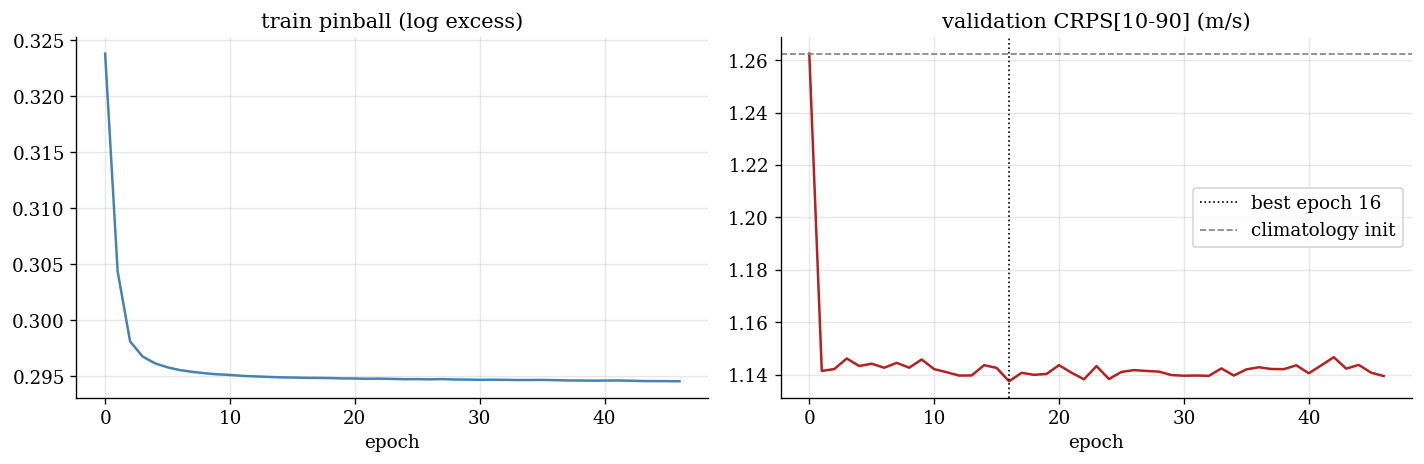

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(HHIST["epoch"], HHIST["train_pinball"], color="steelblue")
ax[0].set_title("train pinball (log excess)"); ax[0].set_xlabel("epoch"); ax[0].grid(alpha=0.3)
ax[1].plot(HHIST["epoch"], HHIST["val_crps"], color="firebrick")
ax[1].axvline(best_ep, color="k", ls=":", lw=1, label=f"best epoch {best_ep}")
ax[1].axhline(HHIST["val_crps"][0], color="gray", ls="--", lw=1, label="climatology init")
ax[1].set_title("validation CRPS[10-90] (m/s)"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(BASE/"wmax_head_v4_train.png", bbox_inches="tight"); plt.show()

In [27]:
# test and validation forecasts in m/s, sorted
w_q_te, w_y_te = to_ms(predict_log("test"), D["test"]["y_log"])
w_q_va, w_y_va = to_ms(predict_log("val"),  D["val"]["y_log"])
print(f"window-max positives | val {len(w_y_va):,}  test {len(w_y_te):,}  (scored in m/s)")

# climatological reference: training-period window-max excess distribution (m/s)
w_q_clim = np.quantile(CLIM_WMAX, W_TAU)
w_crps = w_crps_quant(w_y_te, w_q_te)
w_crps_clim = w_crps_quant(w_y_te, np.repeat(w_q_clim[None, :], len(w_y_te), axis=0))
w_skill = 100.0 * (1.0 - w_crps / w_crps_clim)

w_i50 = W_TAU.tolist().index(0.50)
w_med = w_q_te[:, w_i50]
w_mae = float(np.abs(w_y_te - w_med).mean())
w_cov80 = float(((w_y_te >= w_q_te[:, 0]) & (w_y_te <= w_q_te[:, -1])).mean())
w_mae_clim = float(np.abs(w_y_te - w_q_clim[w_i50]).mean())

# split conformal on the window-max residuals (validation -> test)
w_med_va = w_q_va[:, w_i50]
w_half = float(np.quantile(np.abs(w_y_va - w_med_va), 0.90))
w_cov_conf = float((np.abs(w_y_te - w_med) <= w_half).mean())

# per-tau pinball in m/s, for the log
_d = w_y_te[:, None] - w_q_te; _t = W_TAU[None, :]
_pb = np.mean(np.maximum(_t*_d, (_t-1)*_d), axis=0)
_dc = w_y_te[:, None] - w_q_clim[None, :]; _pbc = np.mean(np.maximum(_t*_dc, (_t-1)*_dc), axis=0)

# reference only: the jointly trained head stored in heich_cr_best.pt, on the same rows
_qj, _ = to_ms(D["test"]["wq_joint"], D["test"]["y_log"])
_j_crps = w_crps_quant(w_y_te, _qj); _j_skill = 100*(1 - _j_crps/w_crps_clim)
_j_cov = float(((w_y_te >= _qj[:, 0]) & (w_y_te <= _qj[:, -1])).mean())

print("-" * 72)
print("SURVIVAL MODEL, FROZEN-TRUNK HEAD (v4), SHARED SEVERITY TARGET (test positives, m/s)")
print(f"  MAE of the median forecast {w_mae:8.3f} m/s   (climatology {w_mae_clim:.3f})")
print(f"  CRPS[10-90]                {w_crps:8.4f}       climatology {w_crps_clim:.4f}")
print(f"  CRPS skill vs climatology  {w_skill:8.2f} %")
print(f"  coverage of the 10-90 band {w_cov80:8.3f}       nominal 0.800")
print(f"  split conformal            half-width {w_half:.3f} m/s -> coverage {w_cov_conf:.3f} (nominal 0.900)")
print("  pinball by tau (m/s):  " + "  ".join(f"{t:.2f}:{p:.4f}/{c:.4f}" for t, p, c in zip(W_TAU, _pb, _pbc))
      + "   (model/climatology)")
print(f"  [reference] joint head stored in {CKPT.name}: skill {_j_skill:.2f} %, coverage {_j_cov:.3f}")
print("-" * 72)

# same keys as wmax_severity_results.json from the survival notebook
WMAX_RESULTS = {"n_test": int(len(w_y_te)), "mae_of_median_ms": w_mae,
                "crps": w_crps, "crps_clim": w_crps_clim, "crps_skill_pct": w_skill,
                "coverage_10_90": w_cov80, "conformal_half_width": w_half,
                "conformal_coverage": w_cov_conf, "tau": list(W_TAU),
                "checkpoint": str(CKPT_V4)}
json.dump(WMAX_RESULTS, open(RESULTS_JSON, "w"), indent=2)

FITLOG = {"results_file": RESULTS_JSON.name, "cache_meta": META,
          "trunk_checkpoint": CKPT.name, "trunk_md5": CKPT_MD5, "head_checkpoint": CKPT_V4.name,
          "trainable_params": ["lin_wq.weight", "lin_wq.bias", "ai_wq.weight", "ai_wq.bias"],
          "init": "zero weights; biases at training log-excess quantiles " + str(np.round(Q0_LOG, 5).tolist()),
          "optimiser": {"name": "AdamW", "lr": CFG.HEAD_LR, "weight_decay_weights": CFG.HEAD_WD,
                        "batch": CFG.HEAD_BATCH, "max_epochs": CFG.HEAD_EPOCHS, "patience": CFG.HEAD_PATIENCE},
          "best_epoch": best_ep, "best_val_crps": best_crps, "init_val_crps": HHIST["val_crps"][0],
          "epochs_run": HHIST["epoch"][-1], "history": HHIST,
          "mae_of_median_clim_ms": w_mae_clim,
          "pinball_by_tau_ms": dict(zip(map(str, W_TAU), map(float, _pb))),
          "pinball_by_tau_clim_ms": dict(zip(map(str, W_TAU), map(float, _pbc))),
          "joint_head_same_rows": {"crps_skill_pct": _j_skill, "coverage_10_90": _j_cov},
          "rows": {sp: int(len(D[sp]["y_log"])) for sp in D}}
json.dump(FITLOG, open(FITLOG_JSON, "w"), indent=2)
print(f"saved -> {RESULTS_JSON.name} (same keys as v3) and {FITLOG_JSON.name}")
print("heich_cr_summary.json was not written by this notebook.")

print()
print("=" * 100)
print(f"WINDOW-MAX SEVERITY | v4 frozen-trunk head: CRPS skill {w_skill:+.1f}% , 10-90 coverage {w_cov80:.3f}"
      f"  ||  v3 joint head: {OLD_V3_SKILL:+.1f}% , {OLD_V3_COV:.3f}"
      f"  ||  CIGB: {CIGB_SKILL:+.1f}% , {CIGB_COV:.3f}")
print(f"                    | change vs v3: {w_skill-OLD_V3_SKILL:+.1f} skill points, coverage {w_cov80-OLD_V3_COV:+.3f}"
      f" | gap to CIGB: {w_skill-CIGB_SKILL:+.1f} skill points, coverage {w_cov80-CIGB_COV:+.3f}")
print("=" * 100)

window-max positives | val 179,300  test 201,360  (scored in m/s)
------------------------------------------------------------------------
SURVIVAL MODEL, FROZEN-TRUNK HEAD (v4), SHARED SEVERITY TARGET (test positives, m/s)
  MAE of the median forecast    1.754 m/s   (climatology 1.922)
  CRPS[10-90]                  1.1107       climatology 1.2188
  CRPS skill vs climatology      8.87 %
  coverage of the 10-90 band    0.799       nominal 0.800
  split conformal            half-width 4.008 m/s -> coverage 0.904 (nominal 0.900)
  pinball by tau (m/s):  0.10:0.2628/0.2772  0.25:0.5758/0.6210  0.50:0.8769/0.9611  0.75:0.8159/0.9041  0.90:0.5074/0.5774   (model/climatology)
  [reference] joint head stored in heich_cr_best.pt: skill -3.51 %, coverage 0.715
------------------------------------------------------------------------
saved -> wmax_severity_results_v4.json (same keys as v3) and wmax_head_fit_v4_log.json
heich_cr_summary.json was not written by this notebook.

WINDOW-MAX SEVERITY |